<a href="https://colab.research.google.com/github/ayudewanti14/implementasi6/blob/main/implementasi6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [5]:
IMG_SIZE = 32
N_CHANNELS = 6
N_PER_CLASS = 400

class_names = [
    "Pertanian skala kecil",
    "Pembangunan jalan",
    "Penebangan selektif",
    "Pertambangan",
    "Gangguan lain/alami"
]

def make_sample(class_id, size=IMG_SIZE):
    # Latar belakang menyerupai tutupan vegetasi dengan variasi acak.
    img = np.random.normal(0.65, 0.07, (size, size, N_CHANNELS)).astype(np.float32)
    yy, xx = np.mgrid[0:size, 0:size]

    # Tambahkan pola buatan yang berbeda untuk setiap kelas.
    if class_id == 0:  # pembukaan lahan berbentuk bidang
        x0, y0 = np.random.randint(4, 13, size=2)
        w, h = np.random.randint(8, 16, size=2)
        mask = (xx >= x0) & (xx < min(x0+w, size)) & (yy >= y0) & (yy < min(y0+h, size))
        img[mask] = np.random.normal(0.30, 0.05, (mask.sum(), N_CHANNELS))
    elif class_id == 1:  # jalan memanjang
        center = np.random.randint(9, 23)
        width = np.random.randint(2, 4)
        mask = np.abs(yy - (0.45 * xx + center - 7)) < width
        img[mask] = np.random.normal(0.25, 0.04, (mask.sum(), N_CHANNELS))
    elif class_id == 2:  # beberapa titik/jejak kecil penebangan
        for _ in range(np.random.randint(4, 9)):
            cx, cy = np.random.randint(3, size-3, size=2)
            radius = np.random.randint(1, 3)
            mask = (xx-cx)**2 + (yy-cy)**2 <= radius**2
            img[mask] = np.random.normal(0.32, 0.06, (mask.sum(), N_CHANNELS))
    elif class_id == 3:  # area terbuka lebih besar, menyerupai lokasi tambang
        cx, cy = np.random.randint(10, 23, size=2)
        rx, ry = np.random.randint(5, 10, size=2)
        mask = ((xx-cx)/rx)**2 + ((yy-cy)/ry)**2 < 1
        img[mask] = np.random.normal(0.20, 0.05, (mask.sum(), N_CHANNELS))
        # Variasi tambahan pada kanal tertentu
        img[mask, 0] += 0.15
    else:  # gangguan tidak beraturan
        noise_mask = np.random.random((size, size)) > 0.88
        img[noise_mask] = np.random.normal(0.42, 0.10, (noise_mask.sum(), N_CHANNELS))

    return np.clip(img, 0, 1)

X, y = [], []
for class_id in range(len(class_names)):
    for _ in range(N_PER_CLASS):
        X.append(make_sample(class_id))
        y.append(class_id)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int64)

print("Bentuk data citra:", X.shape)
print("Bentuk label:", y.shape)
print("Jumlah sampel:", len(y))

Bentuk data citra: (2000, 32, 32, 6)
Bentuk label: (2000,)
Jumlah sampel: 2000


In [4]:
IMG_SIZE = 32
N_CHANNELS = 6
N_PER_CLASS = 400

class_names = [
    "Pertanian skala kecil",
    "Pembangunan jalan",
    "Penebangan selektif",
    "Pertambangan",
    "Gangguan lain/alami"
]

def make_sample(class_id, size=IMG_SIZE):
    # Latar belakang menyerupai tutupan vegetasi dengan variasi acak.
    img = np.random.normal(0.65, 0.07, (size, size, N_CHANNELS)).astype(np.float32)
    yy, xx = np.mgrid[0:size, 0:size]

    # Tambahkan pola buatan yang berbeda untuk setiap kelas.
    if class_id == 0:  # pembukaan lahan berbentuk bidang
        x0, y0 = np.random.randint(4, 13, size=2)
        w, h = np.random.randint(8, 16, size=2)
        mask = (xx >= x0) & (xx < min(x0+w, size)) & (yy >= y0) & (yy < min(y0+h, size))
        img[mask] = np.random.normal(0.30, 0.05, (mask.sum(), N_CHANNELS))
    elif class_id == 1:  # jalan memanjang
        center = np.random.randint(9, 23)
        width = np.random.randint(2, 4)
        mask = np.abs(yy - (0.45 * xx + center - 7)) < width
        img[mask] = np.random.normal(0.25, 0.04, (mask.sum(), N_CHANNELS))
    elif class_id == 2:  # beberapa titik/jejak kecil penebangan
        for _ in range(np.random.randint(4, 9)):
            cx, cy = np.random.randint(3, size-3, size=2)
            radius = np.random.randint(1, 3)
            mask = (xx-cx)**2 + (yy-cy)**2 <= radius**2
            img[mask] = np.random.normal(0.32, 0.06, (mask.sum(), N_CHANNELS))
    elif class_id == 3:  # area terbuka lebih besar, menyerupai lokasi tambang
        cx, cy = np.random.randint(10, 23, size=2)
        rx, ry = np.random.randint(5, 10, size=2)
        mask = ((xx-cx)/rx)**2 + ((yy-cy)/ry)**2 < 1
        img[mask] = np.random.normal(0.20, 0.05, (mask.sum(), N_CHANNELS))
        # Variasi tambahan pada kanal tertentu
        img[mask, 0] += 0.15
    else:  # gangguan tidak beraturan
        noise_mask = np.random.random((size, size)) > 0.88
        img[noise_mask] = np.random.normal(0.42, 0.10, (noise_mask.sum(), N_CHANNELS))

    return np.clip(img, 0, 1)

X, y = [], []
for class_id in range(len(class_names)):
    for _ in range(N_PER_CLASS):
        X.append(make_sample(class_id))
        y.append(class_id)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int64)

print("Bentuk data citra:", X.shape)
print("Bentuk label:", y.shape)
print("Jumlah sampel:", len(y))

Bentuk data citra: (2000, 32, 32, 6)
Bentuk label: (2000,)
Jumlah sampel: 2000


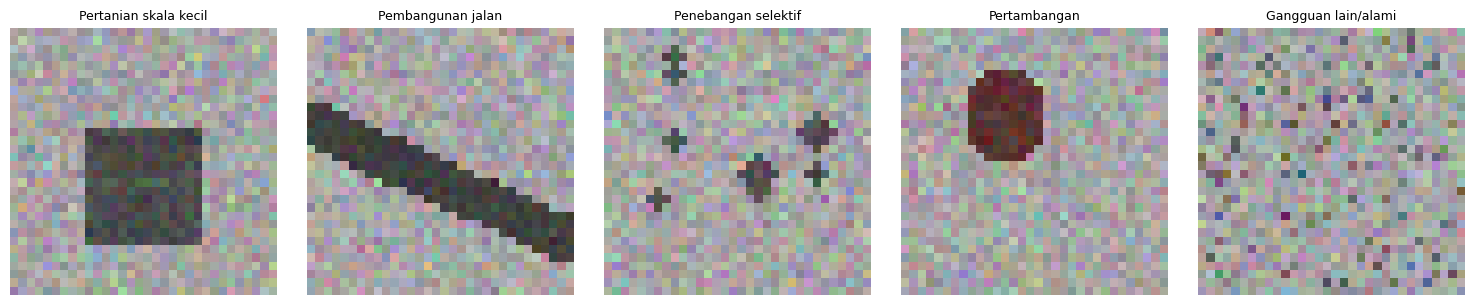

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for class_id, ax in enumerate(axes):
    sample_index = np.where(y == class_id)[0][0]
    ax.imshow(X[sample_index][:, :, :3])
    ax.set_title(class_names[class_id], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Data latih:", X_train.shape[0])
print("Data uji:", X_test.shape[0])

Data latih: 1600
Data uji: 400


In [8]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, N_CHANNELS)),
    tf.keras.layers.Conv2D(16, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,261 (102.58 KB)

 Trainable params: 26,261 (102.58 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=15,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.2258 - loss: 1.6088 - val_accuracy: 0.1375 - val_loss: 1.6042
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.2977 - loss: 1.5726 - val_accuracy: 0.5625 - val_loss: 1.5004
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.4750 - loss: 1.2106 - val_accuracy: 0.7375 - val_loss: 0.8307
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - accuracy: 0.6742 - loss: 0.7941 - val_accuracy: 0.8469 - val_loss: 0.5335
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.7242 - loss: 0.6410 - val_accuracy: 0.9000 - val_loss: 0.4001
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.7891 - loss: 0.5224 - val_accuracy: 0.9406 - val_loss: 0.2967
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.8188 - loss: 0.4239 - val_accuracy: 0.9906 - val_loss: 0.2274
Epoch 8/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.8281 - loss: 0.3834 - val_accuracy: 0.9937 - v

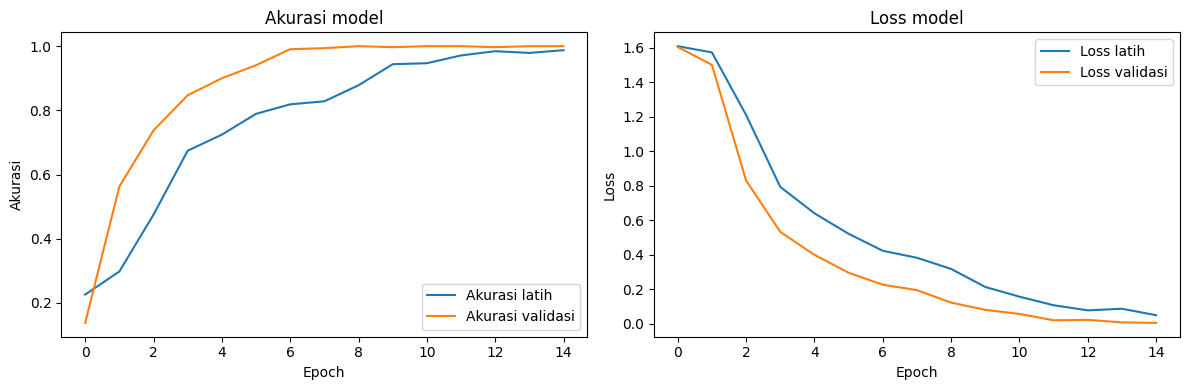

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Akurasi latih")
plt.plot(history.history["val_accuracy"], label="Akurasi validasi")
plt.xlabel("Epoch")
plt.ylabel("Akurasi")
plt.title("Akurasi model")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Loss latih")
plt.plot(history.history["val_loss"], label="Loss validasi")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss model")
plt.legend()

plt.tight_layout()
plt.show()

Akurasi data uji: 1.000
Loss data uji: 0.008

Classification report:
                       precision    recall  f1-score   support

Pertanian skala kecil       1.00      1.00      1.00        80
    Pembangunan jalan       1.00      1.00      1.00        80
  Penebangan selektif       1.00      1.00      1.00        80
         Pertambangan       1.00      1.00      1.00        80
  Gangguan lain/alami       1.00      1.00      1.00        80

             accuracy                           1.00       400
            macro avg       1.00      1.00      1.00       400
         weighted avg       1.00      1.00      1.00       400



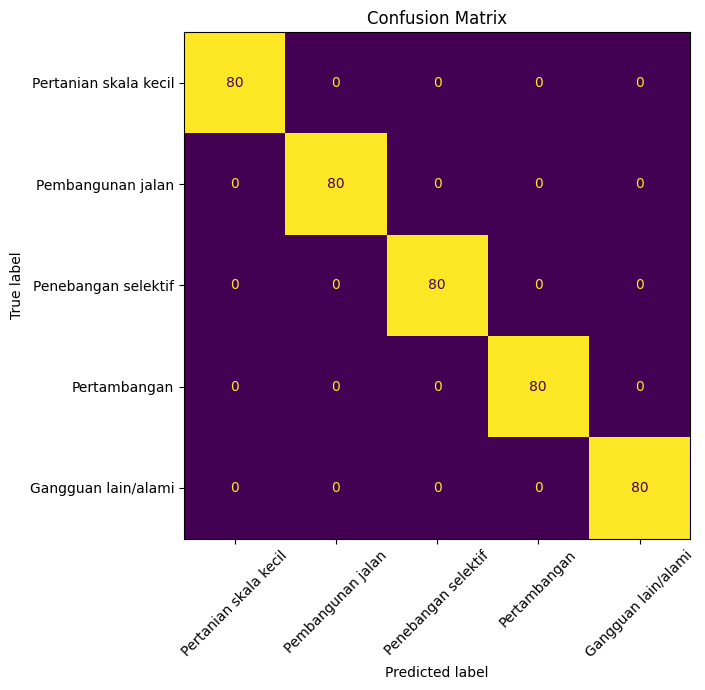

In [11]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi data uji: {test_accuracy:.3f}")
print(f"Loss data uji: {test_loss:.3f}")

y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification report:")
print(classification_report(
    y_test, y_pred, labels=np.arange(len(class_names)),
    target_names=class_names, zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

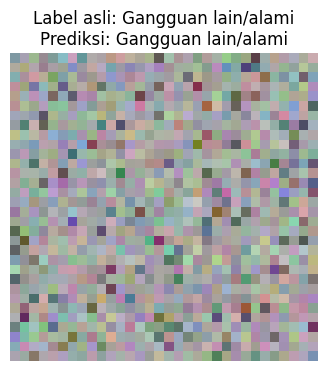

Skor tiap kelas:
Pertanian skala kecil: 0.000
Pembangunan jalan: 0.000
Penebangan selektif: 0.000
Pertambangan: 0.000
Gangguan lain/alami: 1.000


In [12]:
sample_id = 0
sample = X_test[sample_id]
true_label = y_test[sample_id]

probabilities = model.predict(sample[np.newaxis, ...], verbose=0)[0]
pred_label = int(np.argmax(probabilities))

plt.figure(figsize=(4, 4))
plt.imshow(sample[:, :, :3])
plt.title(f"Label asli: {class_names[true_label]}\nPrediksi: {class_names[pred_label]}")
plt.axis("off")
plt.show()

print("Skor tiap kelas:")
for name, score in zip(class_names, probabilities):
    print(f"{name}: {score:.3f}")